<a href="https://colab.research.google.com/github/verma-lokesh/case-study-4-E-Commerce-Customer-Segmentation-/blob/main/CaseStudy3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [22]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.neighbors import NearestNeighbors

sns.set_theme(style="whitegrid")

In [23]:
pip install ucimlrepo

In [24]:
from ucimlrepo import fetch_ucirepo

# fetch dataset
online_retail = fetch_ucirepo(id=352)

# data (as pandas dataframes)
X = online_retail.data.features
y = online_retail.data.targets

# metadata
print(online_retail.metadata)

# variable information
print(online_retail.variables)


{'uci_id': 352, 'name': 'Online Retail', 'repository_url': 'https://archive.ics.uci.edu/dataset/352/online+retail', 'data_url': 'https://archive.ics.uci.edu/static/public/352/data.csv', 'abstract': 'This is a transactional data set which contains all the transactions occurring between 01/12/2010 and 09/12/2011 for a UK-based and registered non-store online retail.', 'area': 'Business', 'tasks': ['Classification', 'Clustering'], 'characteristics': ['Multivariate', 'Sequential', 'Time-Series'], 'num_instances': 541909, 'num_features': 6, 'feature_types': ['Integer', 'Real'], 'demographics': [], 'target_col': None, 'index_col': ['InvoiceNo', 'StockCode'], 'has_missing_values': 'no', 'missing_values_symbol': None, 'year_of_dataset_creation': 2015, 'last_updated': 'Mon Oct 21 2024', 'dataset_doi': '10.24432/C5BW33', 'creators': ['Daqing Chen'], 'intro_paper': {'ID': 361, 'type': 'NATIVE', 'title': 'Data mining for the online retail industry: A case study of RFM model-based customer segmenta

In [25]:
df = online_retail.data.features.copy()

# Add the ID columns
df.insert(0, "InvoiceNo", online_retail.data.ids["InvoiceNo"])
df.insert(1, "StockCode", online_retail.data.ids["StockCode"])

print(df.columns.tolist())
display(df.head())

['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,12/1/2010 8:26,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,12/1/2010 8:26,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,12/1/2010 8:26,3.39,17850.0,United Kingdom


In [26]:
display(df.head())

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,12/1/2010 8:26,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,12/1/2010 8:26,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,12/1/2010 8:26,3.39,17850.0,United Kingdom


In [27]:
display(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   InvoiceNo    541909 non-null  object 
 1   StockCode    541909 non-null  object 
 2   Description  540455 non-null  object 
 3   Quantity     541909 non-null  int64  
 4   InvoiceDate  541909 non-null  object 
 5   UnitPrice    541909 non-null  float64
 6   CustomerID   406829 non-null  float64
 7   Country      541909 non-null  object 
dtypes: float64(2), int64(1), object(5)
memory usage: 33.1+ MB


None

In [28]:
print(df.isnull().sum())

InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64


In [29]:
df = df.dropna(subset=["CustomerID"]).copy()
df["InvoiceNo"] = df["InvoiceNo"].astype(str)

In [30]:
df = df[
    (~df["InvoiceNo"].str.startswith("C")) &
    (df["Quantity"] > 0) &
    (df["UnitPrice"] > 0)
].copy()

In [31]:
df = df.drop_duplicates()

In [32]:
df["CustomerID"] = df["CustomerID"].astype(int)
df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"])
df["Revenue"] = df["Quantity"] * df["UnitPrice"]

In [33]:
snapshot_date = df["InvoiceDate"].max() + pd.Timedelta(days=1)

In [34]:
rfm = df.groupby("CustomerID").agg(
    Recency=("InvoiceDate",
             lambda x: (snapshot_date - x.max()).days),
    Frequency=("InvoiceNo", "nunique"),
    Monetary=("Revenue", "sum")
)

In [35]:
print("Total customers:", len(rfm))

Total customers: 4338


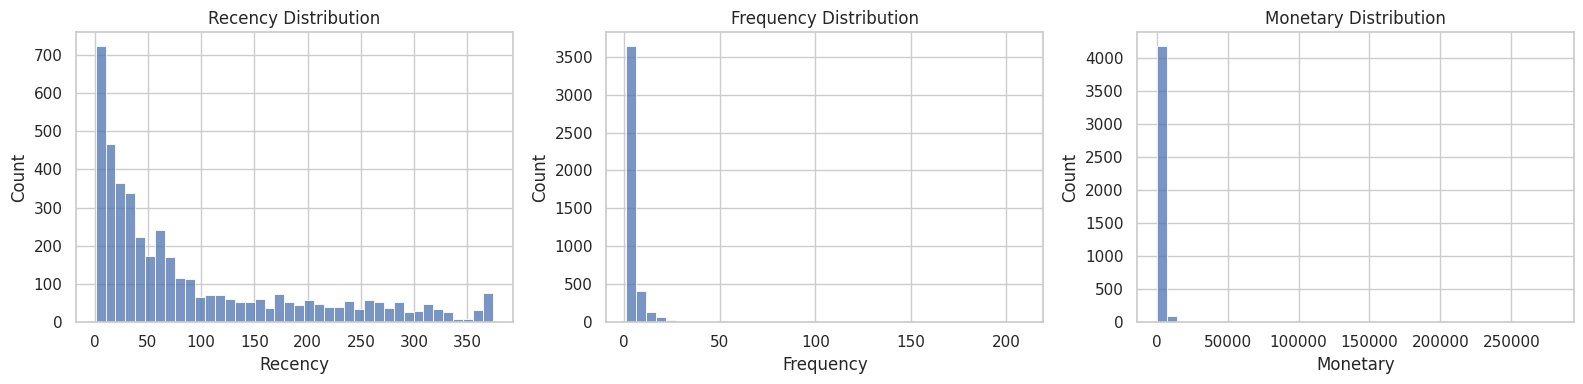

In [36]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col in zip(axes, ["Recency", "Frequency", "Monetary"]):
    sns.histplot(rfm[col], bins=40, ax=ax)
    ax.set_title(f"{col} Distribution")

plt.tight_layout()
plt.show()

In [37]:
features = ["Recency", "Frequency", "Monetary"]

X_log = np.log1p(rfm[features])

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_log)

print("Scaled data shape:", X_scaled.shape)

Scaled data shape: (4338, 3)


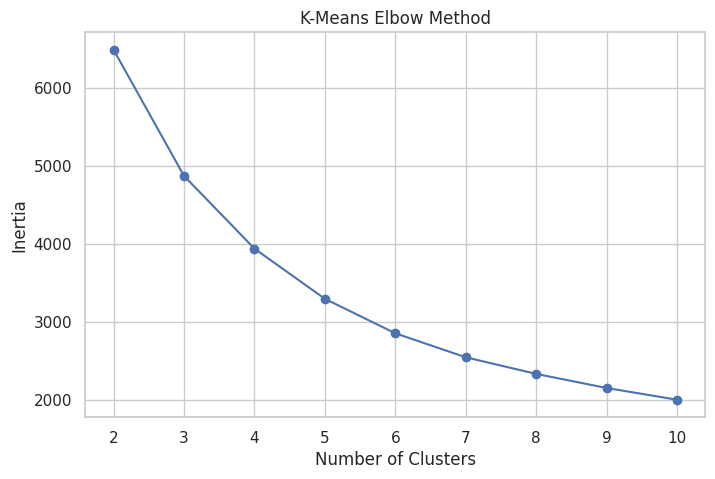

In [38]:
inertias = []

for k in range(2, 11):
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    model.fit(X_scaled)
    inertias.append(model.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(range(2, 11), inertias, marker="o")
plt.xlabel("Number of Clusters")
plt.ylabel("Inertia")
plt.title("K-Means Elbow Method")
plt.show()

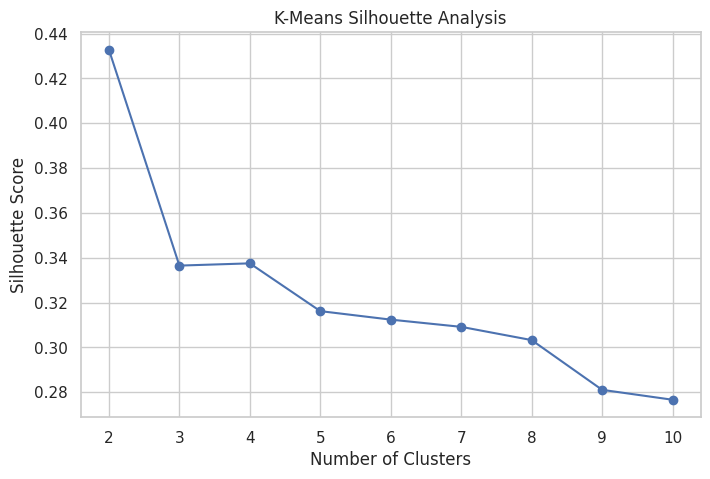

In [39]:
scores = []

for k in range(2, 11):
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = model.fit_predict(X_scaled)
    scores.append(silhouette_score(X_scaled, labels))

plt.figure(figsize=(8, 5))
plt.plot(range(2, 11), scores, marker="o")
plt.xlabel("Number of Clusters")
plt.ylabel("Silhouette Score")
plt.title("K-Means Silhouette Analysis")
plt.show()


In [40]:
best_k = list(range(2, 11))[np.argmax(scores)]

kmeans = KMeans(
    n_clusters=best_k,
    random_state=42,
    n_init=10
)

rfm["KMeans_Cluster"] = kmeans.fit_predict(X_scaled)

print("Selected clusters:", best_k)
print(rfm["KMeans_Cluster"].value_counts().sort_index())

Selected clusters: 2
KMeans_Cluster
0    2672
1    1666
Name: count, dtype: int64


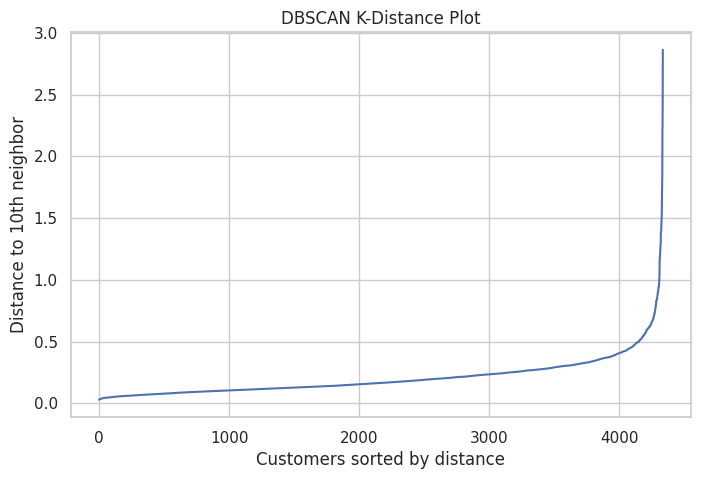

In [41]:
min_samples = 10

neighbors = NearestNeighbors(
    n_neighbors=min_samples
).fit(X_scaled)

distances, _ = neighbors.kneighbors(X_scaled)
k_distances = np.sort(distances[:, -1])

plt.figure(figsize=(8, 5))
plt.plot(k_distances)
plt.xlabel("Customers sorted by distance")
plt.ylabel("Distance to 10th neighbor")
plt.title("DBSCAN K-Distance Plot")
plt.show()

In [42]:
dbscan = DBSCAN(eps=0.8, min_samples=10)

rfm["DBSCAN_Cluster"] = dbscan.fit_predict(X_scaled)

print(rfm["DBSCAN_Cluster"].value_counts().sort_index())

n_clusters = len(set(rfm["DBSCAN_Cluster"])) - (
    1 if -1 in rfm["DBSCAN_Cluster"].values else 0
)

noise = (rfm["DBSCAN_Cluster"] == -1).mean() * 100

print("DBSCAN clusters:", n_clusters)
print(f"Noise customers: {noise:.2f}%")

DBSCAN_Cluster
-1      29
 0    4309
Name: count, dtype: int64
DBSCAN clusters: 1
Noise customers: 0.67%


In [43]:
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

rfm["PCA1"] = X_pca[:, 0]
rfm["PCA2"] = X_pca[:, 1]

print("Explained variance ratio:", pca.explained_variance_ratio_)
print("Total variance captured:",
      round(pca.explained_variance_ratio_.sum(), 4))

Explained variance ratio: [0.75078634 0.18786648]
Total variance captured: 0.9387


In [44]:
tsne = TSNE(
    n_components=2,
    perplexity=30,
    init="pca",
    learning_rate="auto",
    random_state=42
)

X_tsne = tsne.fit_transform(X_scaled)

rfm["tSNE1"] = X_tsne[:, 0]
rfm["tSNE2"] = X_tsne[:, 1]

print("t-SNE completed:", X_tsne.shape)


t-SNE completed: (4338, 2)


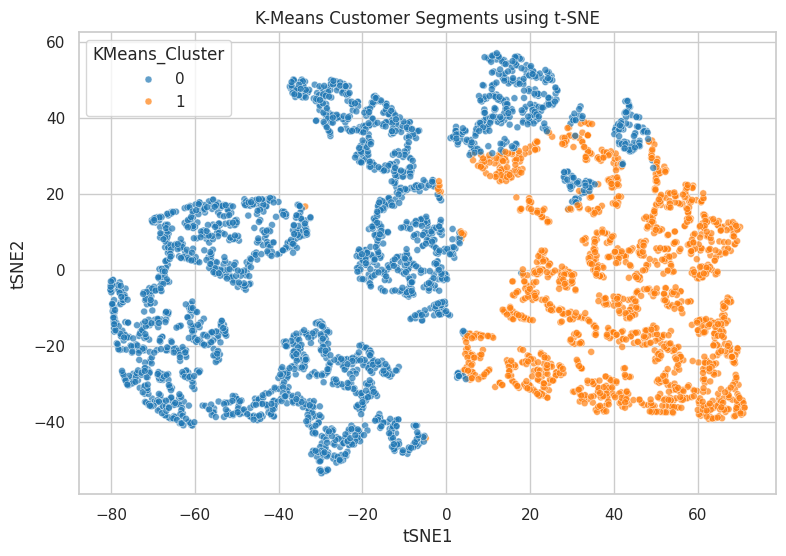

In [45]:
plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=rfm,
    x="tSNE1",
    y="tSNE2",
    hue="KMeans_Cluster",
    palette="tab10",
    s=25,
    alpha=0.7
)

plt.title("K-Means Customer Segments using t-SNE")
plt.show()

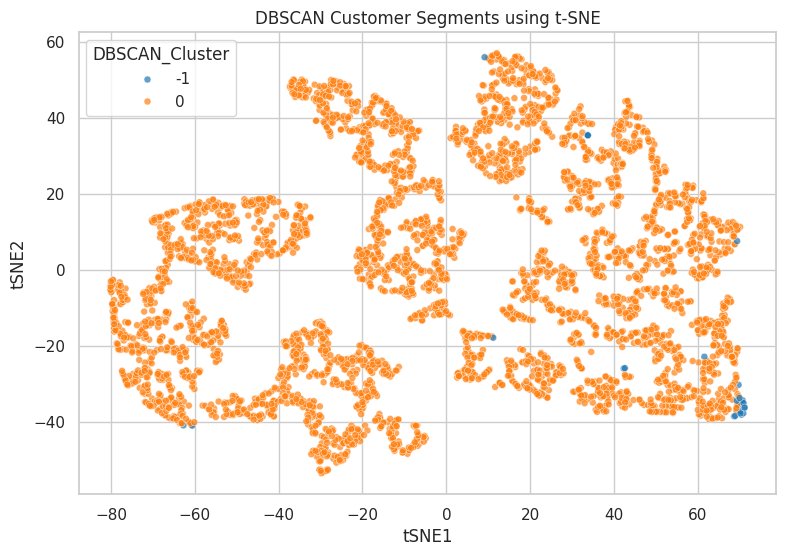

In [46]:
plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=rfm,
    x="tSNE1",
    y="tSNE2",
    hue="DBSCAN_Cluster",
    palette="tab10",
    s=25,
    alpha=0.7
)

plt.title("DBSCAN Customer Segments using t-SNE")
plt.show()

In [47]:
profile = rfm.groupby("KMeans_Cluster").agg(
    Customers=("Recency", "size"),
    Avg_Recency=("Recency", "mean"),
    Avg_Frequency=("Frequency", "mean"),
    Avg_Monetary=("Monetary", "mean"),
    Median_Recency=("Recency", "median"),
    Median_Frequency=("Frequency", "median"),
    Median_Monetary=("Monetary", "median")
).round(2)

profile["Customer_Percent"] = (
    profile["Customers"] / len(rfm) * 100
).round(2)

display(profile)

,Customers,Avg_Recency,Avg_Frequency,Avg_Monetary,Median_Recency,Median_Frequency,Median_Monetary,Customer_Percent
KMeans_Cluster,,,,,,,,
0,2672,134.09,1.67,495.59,96.0,1.0,363.08,61.6
1,1666,25.89,8.44,4539.60,16.0,6.0,2061.08,38.4


In [48]:
med_r = rfm["Recency"].median()
med_f = rfm["Frequency"].median()
med_m = rfm["Monetary"].median()

def assign_persona(row):
    r = row["Median_Recency"]
    f = row["Median_Frequency"]
    m = row["Median_Monetary"]

    if r <= med_r and f >= med_f and m >= med_m:
        return "Champions"
    elif r > med_r and f >= med_f:
        return "At-Risk Loyal Customers"
    elif f >= med_f and m < med_m:
        return "Frequent Low-Spenders"
    elif r <= med_r and m >= med_m:
        return "Recent High-Spenders"
    elif r > med_r and f < med_f:
        return "Hibernating Customers"
    else:
        return "Developing Customers"

profile["Persona"] = profile.apply(assign_persona, axis=1)

display(profile[["Customers", "Customer_Percent", "Persona"]])

,Customers,Customer_Percent,Persona
KMeans_Cluster,,,
0,2672,61.6,Hibernating Customers
1,1666,38.4,Champions
